### TDSP · Fase 3: Selección y evaluación del modelo

Selección del modelo final, ajuste del umbral de decisión y evaluación en el grupo de prueba.

- **Entradas:**
  - `Sample_Data/For_Modeling/train_clean.csv`, `Sample_Data/For_Modeling/test_clean.csv`
  - `Code/Modeling/results/cv_unbalanced.csv`, `Code/Modeling/results/cv_balanced.csv`
- **Salidas:**
  - `Code/Modeling/models/final_model.joblib`, `Code/Modeling/models/model_metadata.json`
  - `Code/Modeling/results/test_metrics.csv`, `Code/Modeling/results/feature_importance.csv`
  - `Docs/Model/figures/`: figuras de la evaluación
- **Variable objetivo:** `Revenue`

#### Librerías

In [1]:
import ast
import json
from pathlib import Path

import imblearn
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline
from matplotlib.colors import LinearSegmentedColormap
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

#### Semilla

In [2]:
# Semilla para reproducibilidad. Puede modificarse o eliminarse.
SEED = 1
np.random.seed(SEED)

#### Rutas

Relativas a la carpeta del notebook.

In [3]:
FOR_MODELING_DIR = Path("../../Sample_Data/For_Modeling")
RESULTS_DIR = Path("results")
MODELS_DIR = Path("models")
FIGURES_DIR = Path("../../Docs/Model/figures")
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

#### Estilo de las figuras

In [4]:
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
    "font.size": 10,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

#### Carga de datos

In [5]:
train = pd.read_csv(FOR_MODELING_DIR / "train_clean.csv")
test = pd.read_csv(FOR_MODELING_DIR / "test_clean.csv")

TARGET = "Revenue"
X_train, y_train = train.drop(columns=["row_id", TARGET]), train[TARGET]
X_test, y_test = test.drop(columns=["row_id", TARGET]), test[TARGET]

print(f"Entrenamiento: {len(X_train):,} | Prueba: {len(X_test):,}")

Entrenamiento: 9,864 | Prueba: 2,466


#### Definiciones compartidas con los notebooks 03 y 04

In [6]:
CATEGORICAL = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
NUMERIC_ALL = [c for c in X_train.columns if c not in CATEGORICAL]
FEATURE_SETS = {
    "con_PageValues": NUMERIC_ALL,
    "sin_PageValues": [c for c in NUMERIC_ALL if c != "PageValues"],
}


def make_preprocessor(numeric):
    return ColumnTransformer(
        [
            ("num", "passthrough", numeric),
            ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30,
                                  sparse_output=False), CATEGORICAL),
        ],
        verbose_feature_names_out=False,
    )


def make_steps(model_name):
    rf = dict(n_estimators=300, random_state=SEED, n_jobs=-1)
    return {
        "referencia": [("model", DummyClassifier(strategy="most_frequent"))],
        "arbol": [("model", DecisionTreeClassifier(random_state=SEED))],
        "rf": [("model", RandomForestClassifier(**rf))],
        "arbol_sobremuestreo": [("sampler", RandomOverSampler(random_state=SEED)),
                                ("model", DecisionTreeClassifier(random_state=SEED))],
        "rf_sobremuestreo": [("sampler", RandomOverSampler(random_state=SEED)),
                             ("model", RandomForestClassifier(**rf))],
        "rf_pesos_de_clase": [("model", RandomForestClassifier(class_weight="balanced", **rf))],
    }[model_name]


def build(model_name, variables, params):
    pipe = Pipeline([("preprocessor", make_preprocessor(FEATURE_SETS[variables]))] + make_steps(model_name))
    return pipe.set_params(**params)

#### Resultados de la validación cruzada

Unión de las dos ejecuciones, ordenada por F1.

In [7]:
cv_all = pd.concat([
    pd.read_csv(RESULTS_DIR / "cv_unbalanced.csv").assign(ejecucion="sin balancear"),
    pd.read_csv(RESULTS_DIR / "cv_balanced.csv").assign(ejecucion="balanceada"),
], ignore_index=True)

cv_all.sort_values("f1_mean", ascending=False)[
    ["ejecucion", "modelo", "variables", "f1_mean", "recall_mean", "precision_mean", "average_precision_mean"]
]

,ejecucion,modelo,variables,f1_mean,recall_mean,precision_mean,average_precision_mean
8,balanceada,rf_pesos_de_clase,con_PageValues,0.6758,0.7883,0.5917,0.7216
7,balanceada,rf_sobremuestreo,con_PageValues,0.6693,0.7870,0.5823,0.7267
6,balanceada,arbol_sobremuestreo,con_PageValues,0.6396,0.8578,0.5103,0.6412
1,sin balancear,arbol,con_PageValues,0.6332,0.5806,0.6971,0.6752
2,sin balancear,rf,con_PageValues,0.6223,0.5262,0.7615,0.7355
10,balanceada,rf_sobremuestreo,sin_PageValues,0.4257,0.5170,0.3619,0.3750
11,balanceada,rf_pesos_de_clase,sin_PageValues,0.4220,0.6429,0.3142,0.3676
9,balanceada,arbol_sobremuestreo,sin_PageValues,0.3797,0.7503,0.2554,0.3217
4,sin balancear,arbol,sin_PageValues,0.2925,0.3099,0.2771,0.1935
5,sin balancear,rf,sin_PageValues,0.1205,0.0688,0.5008,0.3591


#### Selección del modelo

Criterio: la configuración con mayor F1 en validación cruzada, sin contar el modelo de referencia.

In [8]:
best = cv_all[cv_all["modelo"] != "referencia"].sort_values("f1_mean", ascending=False).iloc[0]
best_params = ast.literal_eval(best["parametros"])

print(f"Ejecución: {best['ejecucion']}")
print(f"Modelo:    {best['modelo']}")
print(f"Variables: {best['variables']}")
print(f"Parámetros: {best_params}")
print(f"F1 en validación cruzada: {best['f1_mean']:.3f}")

Ejecución: balanceada
Modelo:    rf_pesos_de_clase
Variables: con_PageValues
Parámetros: {'model__max_depth': None, 'model__min_samples_leaf': 5}
F1 en validación cruzada: 0.676


#### Probabilidades fuera de pliegue

Cada sesión de entrenamiento recibe una probabilidad calculada por un modelo que no la vio al entrenar. Sirven para ajustar el umbral sin usar el grupo de prueba.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_proba = cross_val_predict(
    build(best["modelo"], best["variables"], best_params),
    X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1,
)[:, 1]

#### Ajuste del umbral de decisión

Umbral con mayor F1 entre los que cumplen una sensibilidad de al menos 0.70 (criterio C2 del acta).

In [10]:
MIN_RECALL = 0.70

precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)
precision, recall = precision[:-1], recall[:-1]
f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)

valid = recall >= MIN_RECALL
best_i = np.argmax(np.where(valid, f1, -1))
THRESHOLD = float(thresholds[best_i])

print(f"Umbral elegido: {THRESHOLD:.3f}")
print(f"En entrenamiento (fuera de pliegue): F1 = {f1[best_i]:.3f} | "
      f"sensibilidad = {recall[best_i]:.3f} | precisión = {precision[best_i]:.3f}")

Umbral elegido: 0.582
En entrenamiento (fuera de pliegue): F1 = 0.680 | sensibilidad = 0.712 | precisión = 0.650


#### Precisión, sensibilidad y F1 según el umbral

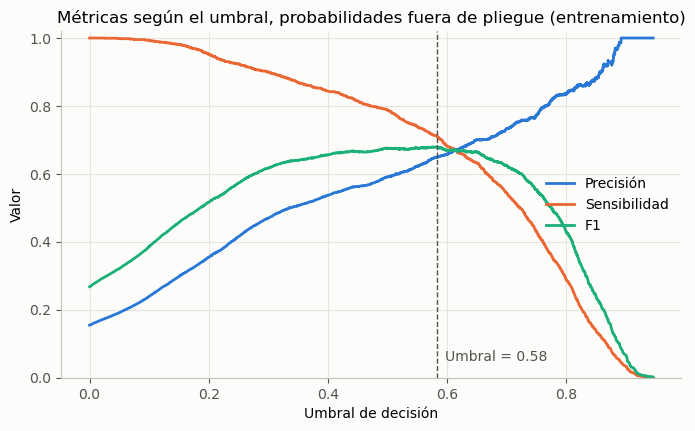

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thresholds, precision, color="#2a78d6", linewidth=2, label="Precisión")
ax.plot(thresholds, recall, color="#eb6834", linewidth=2, label="Sensibilidad")
ax.plot(thresholds, f1, color="#1baf7a", linewidth=2, label="F1")
ax.axvline(THRESHOLD, color="#52514e", linestyle="--", linewidth=1)
ax.annotate(f"Umbral = {THRESHOLD:.2f}", (THRESHOLD, 0.05), xytext=(6, 0),
            textcoords="offset points", color="#52514e")
ax.set_xlabel("Umbral de decisión")
ax.set_ylabel("Valor")
ax.set_ylim(0, 1.02)
ax.legend(loc="center right")
ax.set_title("Métricas según el umbral, probabilidades fuera de pliegue (entrenamiento)")
fig.savefig(FIGURES_DIR / "threshold_curve.png")
plt.show()

#### Entrenamiento final

El modelo elegido, su versión sin `PageValues` y el modelo de referencia se entrenan con todo el grupo de entrenamiento.

In [12]:
same_model_no_pv = cv_all[(cv_all["modelo"] == best["modelo"]) & (cv_all["variables"] == "sin_PageValues")].iloc[0]

final_model = build(best["modelo"], best["variables"], best_params).fit(X_train, y_train)
model_no_pv = build(
    best["modelo"], "sin_PageValues", ast.literal_eval(same_model_no_pv["parametros"])
).fit(X_train, y_train)
baseline = build("referencia", "con_PageValues", {}).fit(X_train, y_train)

#### Evaluación en el grupo de prueba

Primera y única vez que se usa el grupo de prueba.

In [13]:
def evaluate(name, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {
        "modelo": name,
        "umbral": threshold,
        "f1": f1_score(y_test, pred, zero_division=0),
        "sensibilidad": recall_score(y_test, pred, zero_division=0),
        "precision": precision_score(y_test, pred, zero_division=0),
        "average_precision": average_precision_score(y_test, proba),
        "exactitud": (pred == y_test).mean(),
    }


proba_final = final_model.predict_proba(X_test)[:, 1]
proba_no_pv = model_no_pv.predict_proba(X_test)[:, 1]
proba_base = baseline.predict_proba(X_test)[:, 1]

test_metrics = pd.DataFrame([
    evaluate("referencia", proba_base, 0.5),
    evaluate(f"{best['modelo']} (umbral 0.50)", proba_final, 0.5),
    evaluate(f"{best['modelo']} (umbral ajustado)", proba_final, THRESHOLD),
    evaluate(f"{best['modelo']} sin PageValues (umbral 0.50)", proba_no_pv, 0.5),
]).round(4)
test_metrics

,modelo,umbral,f1,sensibilidad,precision,average_precision,exactitud
0,referencia,0.5000,0.0000,0.0000,0.0000,0.1549,0.8451
1,rf_pesos_de_clase (umbral 0.50),0.5000,0.6652,0.7775,0.5812,0.7600,0.8788
2,rf_pesos_de_clase (umbral ajustado),0.5823,0.6976,0.7277,0.6699,0.7600,0.9023
3,rf_pesos_de_clase sin PageValues (umbral 0.50),0.5000,0.4226,0.6859,0.3054,0.3831,0.7097


#### Verificación de los criterios de aceptación

Criterios C1 a C3 del acta del proyecto, con el modelo final y el umbral ajustado.

In [14]:
final_row = test_metrics.iloc[2]
base_row = test_metrics.iloc[0]

criteria = pd.DataFrame([
    {"criterio": "C1. F1 >= 0.60", "resultado": round(final_row["f1"], 3),
     "cumple": final_row["f1"] >= 0.60},
    {"criterio": "C2. Sensibilidad >= 0.70", "resultado": round(final_row["sensibilidad"], 3),
     "cumple": final_row["sensibilidad"] >= 0.70},
    {"criterio": "C3. F1 mayor que la referencia",
     "resultado": f"{final_row['f1']:.3f} frente a {base_row['f1']:.3f}",
     "cumple": final_row["f1"] > base_row["f1"]},
])
criteria

,criterio,resultado,cumple
0,C1. F1 >= 0.60,0.698,True
1,C2. Sensibilidad >= 0.70,0.728,True
2,C3. F1 mayor que la referencia,0.698 frente a 0.000,True


#### Matriz de confusión

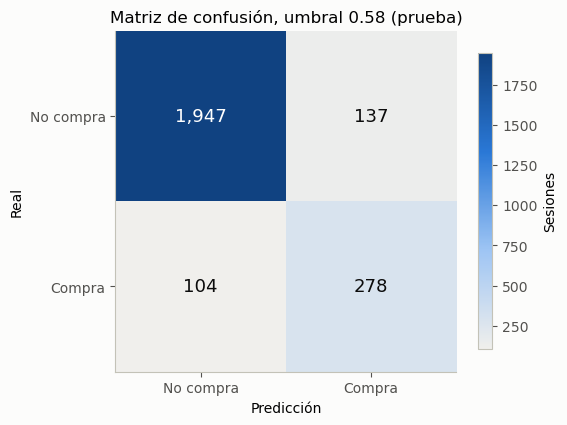

In [15]:
pred_final = (proba_final >= THRESHOLD).astype(int)
cm = confusion_matrix(y_test, pred_final)
labels = ["No compra", "Compra"]
cmap = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#9ec5f4", "#2a78d6", "#104281"])

fig, ax = plt.subplots(figsize=(5.5, 4.8))
im = ax.imshow(cm, cmap=cmap)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=13,
                color="#ffffff" if cm[i, j] > cm.max() / 2 else "#0b0b0b")
ax.set_xticks([0, 1], labels)
ax.set_yticks([0, 1], labels)
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
ax.grid(False)
ax.set_title(f"Matriz de confusión, umbral {THRESHOLD:.2f} (prueba)")
fig.colorbar(im, ax=ax, shrink=0.8, label="Sesiones")
fig.savefig(FIGURES_DIR / "confusion_matrix.png")
plt.show()

#### Importancia de las variables

Importancia por reducción de impureza del Random Forest. Las 15 variables más importantes.

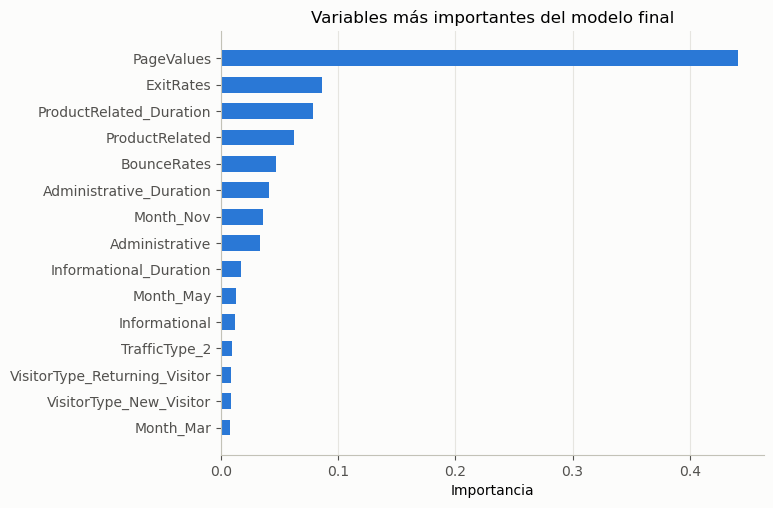

,importancia
PageValues,0.4411
ExitRates,0.0860
ProductRelated_Duration,0.0780
ProductRelated,0.0620
BounceRates,0.0467
Administrative_Duration,0.0410
Month_Nov,0.0357
Administrative,0.0331
Informational_Duration,0.0166
Month_May,0.0123


In [16]:
names = final_model.named_steps["preprocessor"].get_feature_names_out()
importance = pd.Series(final_model.named_steps["model"].feature_importances_, index=names)
importance = importance.sort_values(ascending=False)

top = importance.head(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top.index, top.values, color="#2a78d6", height=0.6)
ax.set_xlabel("Importancia")
ax.grid(axis="y", visible=False)
ax.set_title("Variables más importantes del modelo final")
fig.savefig(FIGURES_DIR / "feature_importance.png")
plt.show()

importance.head(15).round(4).to_frame("importancia")

#### Guardado de resultados

El archivo de metadatos guarda el umbral y las variables que necesita el script de predicción.

In [17]:
metadata = {
    "modelo": best["modelo"],
    "ejecucion": best["ejecucion"],
    "parametros": best_params,
    "umbral": THRESHOLD,
    "variables": list(X_train.columns),
    "categoricas": CATEGORICAL,
    "semilla": SEED,
    "metricas_validacion_cruzada": {
        k: float(best[f"{k}_mean"]) for k in ["f1", "recall", "precision", "average_precision"]
    },
    "metricas_prueba": {k: float(v) for k, v in final_row.drop(["modelo"]).items()},
    "versiones": {"scikit-learn": sklearn.__version__, "imbalanced-learn": imblearn.__version__,
                  "pandas": pd.__version__, "numpy": np.__version__},
}

joblib.dump(final_model, MODELS_DIR / "final_model.joblib", compress=3)
(MODELS_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False))
test_metrics.to_csv(RESULTS_DIR / "test_metrics.csv", index=False)
importance.round(6).to_frame("importancia").to_csv(RESULTS_DIR / "feature_importance.csv")

for path in [
    MODELS_DIR / "final_model.joblib",
    MODELS_DIR / "model_metadata.json",
    RESULTS_DIR / "test_metrics.csv",
    RESULTS_DIR / "feature_importance.csv",
]:
    print(f"Guardado: {path}")

Guardado: models\final_model.joblib
Guardado: models\model_metadata.json
Guardado: results\test_metrics.csv
Guardado: results\feature_importance.csv
